# 01 · Exploración clínica, hitos quirúrgicos y terapia de lenguaje

## Introducción
La rehabilitación de la fisura labiopalatina no se reduce a una cirugía: combina
**queiloplastia**, **palatoplastia**, control de complicaciones (dehiscencia, fístula)
y un programa prolongado de **terapia de lenguaje**, a menudo con
insuficiencia velofaríngea (IVF) e hipernasalidad.

Este notebook usa el dataset unificado `data/processed/dataset_final_limpio.csv`,
derivado de los seis CSV de `data/raw/`.

## Preguntas
1. ¿A qué edad ocurren los hitos quirúrgicos y cuál es el intervalo entre ellos?
2. ¿Cómo se relacionan las complicaciones con el número de cirugías?
3. ¿La asistencia a terapia, la IVF y la hipernasalidad describen trayectorias distintas?


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})

CANDIDATES = [Path.cwd(), Path.cwd().parent]
ROOT = next(
    path for path in CANDIDATES
    if (path / "data" / "processed" / "dataset_final_limpio.csv").exists()
    or (path / "data" / "raw" / "dataset_desercion_fisura_bilabial.csv").exists()
)
PROCESSED = ROOT / "data" / "processed" / "dataset_final_limpio.csv"
RAW = ROOT / "data" / "raw"
print(f"Raíz del proyecto: {ROOT}")


Raíz del proyecto: C:\Users\richa\Downloads\Proyecto-predicci-n-de-desertamiento-del-tratamiento-de-fisura-bilabial


In [2]:
if not PROCESSED.exists():
    raise FileNotFoundError(
        "No existe dataset_final_limpio.csv. Ejecuta primero "
        "notebooks/00_procesamiento_dataset_unificado.py"
    )
df = pd.read_csv(PROCESSED)
print(df.shape)
print(df.dtypes)
df.head()


(3500, 31)
id_paciente                           str
cohorte                               str
tipo_fisura                           str
fisura_Completa                     int64
fisura_Asimetrica                   int64
fisura_Incompleta                   int64
edad_inicio_meses                   int64
distancia_hospital_km             float64
nivel_socioeconomico                  str
nivel_socioeconomico_ord            int64
ingresos_mensuales_usd              int64
apoyo_psicologico                   int64
cirugias_programadas              float64
citas_asistidas                   float64
citas_asistidas_imputada            int64
citas_perdidas_noshow               int64
edad_queiloplastia_meses          float64
edad_palatoplastia_meses          float64
intervalo_cirugias_meses          float64
dificultad_alimentacion_preop       int64
dehiscencia_herida_postop           int64
fistula_palatina_residual           int64
complicaciones_quirurgicas          int64
peso_z_score_2anos     

,id_paciente,cohorte,tipo_fisura,fisura_Completa,fisura_Asimetrica,fisura_Incompleta,edad_inicio_meses,distancia_hospital_km,nivel_socioeconomico,nivel_socioeconomico_ord,...,fistula_palatina_residual,complicaciones_quirurgicas,peso_z_score_2anos,citas_terapia_programadas,citas_terapia_asistidas,ratio_asistencia_terapia,hipoacusia_conductiva,grado_hipernasalidad,insuficiencia_velofaringea_ivf,desertor
0,PAC-1000,v1,Completa,1,0,0,6,46.9,Alto,4,...,1,1,0.16,20,15,0.750000,0,2,1,1
1,PAC-1001,v1,Asimetrica,0,1,0,1,59.3,Bajo,0,...,0,0,-0.37,47,46,0.978723,0,3,1,1
2,PAC-1002,v1,Incompleta,0,0,1,9,9.2,Medio,2,...,0,0,-0.25,43,31,0.720930,1,0,0,1
3,PAC-1003,v1,Incompleta,0,0,1,1,88.2,Medio,2,...,0,0,-1.07,22,14,0.636364,0,2,1,1
4,PAC-1004,v1,Completa,1,0,0,5,19.1,Bajo,0,...,0,0,-2.21,35,33,0.942857,1,3,1,1


## Variables analizadas
| Grupo | Variables |
|---|---|
| Identidad | `id_paciente`, `cohorte`, `tipo_fisura` |
| Hitos quirúrgicos | `edad_queiloplastia_meses`, `edad_palatoplastia_meses`, `intervalo_cirugias_meses`, `cirugias_programadas` |
| Complicaciones | `dehiscencia_herida_postop`, `fistula_palatina_residual`, `complicaciones_quirurgicas`, `dificultad_alimentacion_preop` |
| Terapia | `citas_terapia_programadas`, `citas_terapia_asistidas`, `ratio_asistencia_terapia` |
| Habla / oído | `grado_hipernasalidad`, `insuficiencia_velofaringea_ivf`, `hipoacusia_conductiva` |
| Crecimiento | `peso_z_score_2anos` |


In [3]:
clinicas = [
    "edad_queiloplastia_meses",
    "edad_palatoplastia_meses",
    "intervalo_cirugias_meses",
    "cirugias_programadas",
    "complicaciones_quirurgicas",
    "citas_terapia_programadas",
    "citas_terapia_asistidas",
    "ratio_asistencia_terapia",
    "grado_hipernasalidad",
    "peso_z_score_2anos",
]
df[clinicas].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
edad_queiloplastia_meses,3500.0,4.66,1.33,3.00,3.50,4.50,5.60,9.80
edad_palatoplastia_meses,3500.0,12.76,2.29,9.00,11.00,12.70,14.20,20.80
intervalo_cirugias_meses,3500.0,8.10,1.88,2.60,6.70,8.00,9.40,15.00
cirugias_programadas,3500.0,2.45,0.81,2.00,2.00,2.00,3.00,5.00
complicaciones_quirurgicas,3500.0,0.25,0.53,0.00,0.00,0.00,0.00,2.00
citas_terapia_programadas,3500.0,34.53,8.63,20.00,27.00,35.00,42.00,49.00
citas_terapia_asistidas,3500.0,16.39,10.20,2.00,8.00,14.00,23.00,48.00
ratio_asistencia_terapia,3500.0,0.47,0.26,0.07,0.25,0.41,0.72,0.98
grado_hipernasalidad,3500.0,1.25,0.92,0.00,1.00,1.00,2.00,3.00
peso_z_score_2anos,3500.0,-0.71,1.06,-4.00,-1.40,-0.71,0.00,2.50


## Hitos quirúrgicos: edades y ventana entre labio y paladar


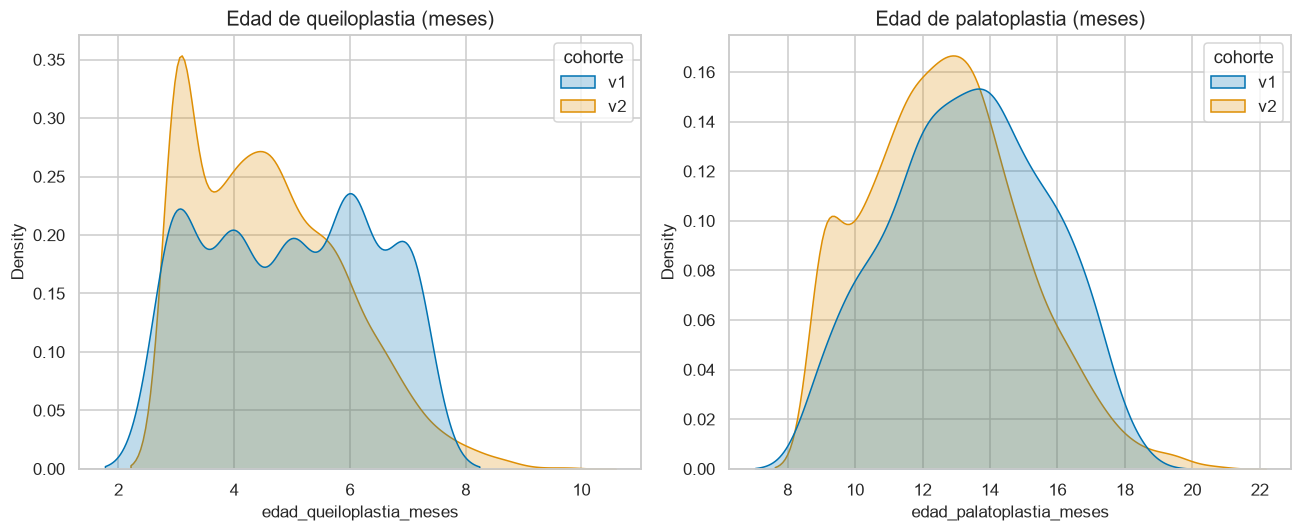

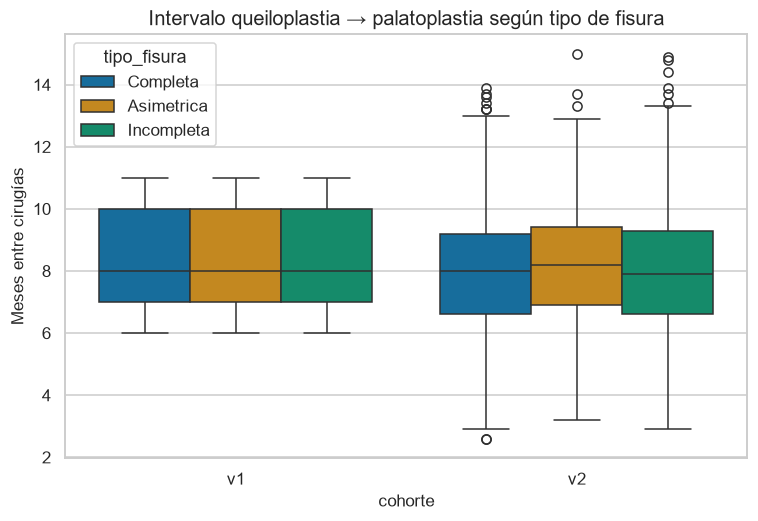

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.kdeplot(
    data=df, x="edad_queiloplastia_meses", hue="cohorte",
    fill=True, common_norm=False, ax=axes[0],
)
axes[0].set_title("Edad de queiloplastia (meses)")
sns.kdeplot(
    data=df, x="edad_palatoplastia_meses", hue="cohorte",
    fill=True, common_norm=False, ax=axes[1],
)
axes[1].set_title("Edad de palatoplastia (meses)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df, x="cohorte", y="intervalo_cirugias_meses",
    hue="tipo_fisura", ax=ax,
)
ax.set_title("Intervalo queiloplastia → palatoplastia según tipo de fisura")
ax.set_ylabel("Meses entre cirugías")
plt.show()


## Número de cirugías y complicaciones
`cirugias_programadas` en v1 viene del CSV de deserción; en v2 se reconstruye
con hitos protocolarios más reoperaciones asociadas a dehiscencia o fístula.


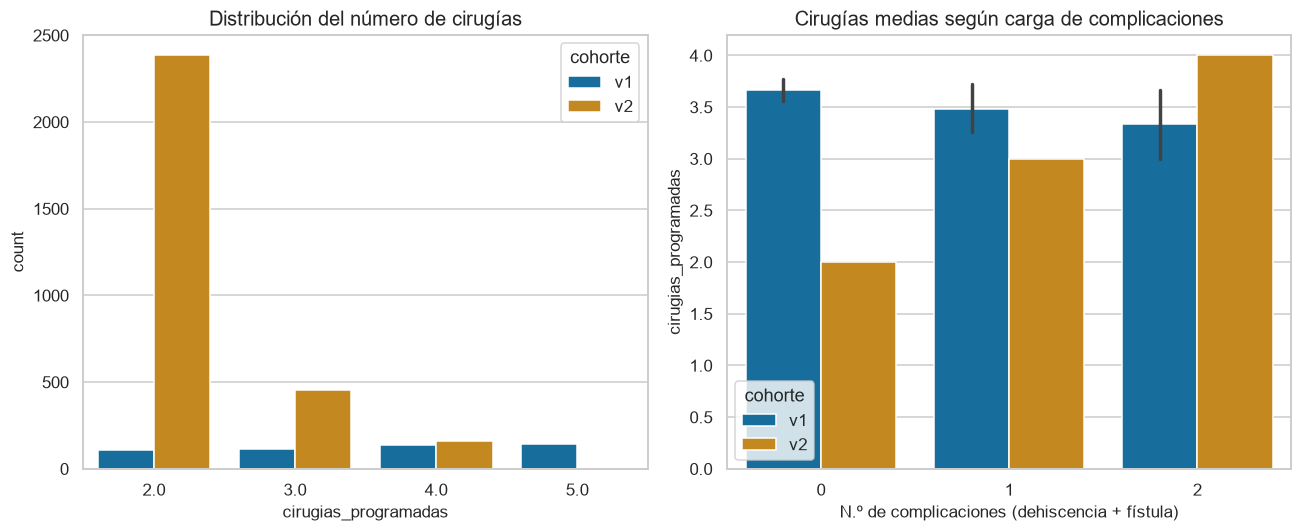

,dehiscencia,fistula,dificultad_alimentacion_preop
cohorte,,,
v1,0.082,0.13,0.252
v2,0.120,0.14,0.641


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(
    data=df, x="cirugias_programadas", hue="cohorte", ax=axes[0],
)
axes[0].set_title("Distribución del número de cirugías")
sns.barplot(
    data=df,
    x="complicaciones_quirurgicas",
    y="cirugias_programadas",
    hue="cohorte",
    errorbar=("ci", 95),
    ax=axes[1],
)
axes[1].set_title("Cirugías medias según carga de complicaciones")
axes[1].set_xlabel("N.º de complicaciones (dehiscencia + fístula)")
fig.tight_layout()
plt.show()

comp_rate = (
    df.assign(
        dehiscencia=df["dehiscencia_herida_postop"].astype(int),
        fistula=df["fistula_palatina_residual"].astype(int),
    )
    .groupby("cohorte")[["dehiscencia", "fistula", "dificultad_alimentacion_preop"]]
    .mean()
    .round(3)
)
comp_rate


## Terapia de lenguaje, IVF e hipernasalidad


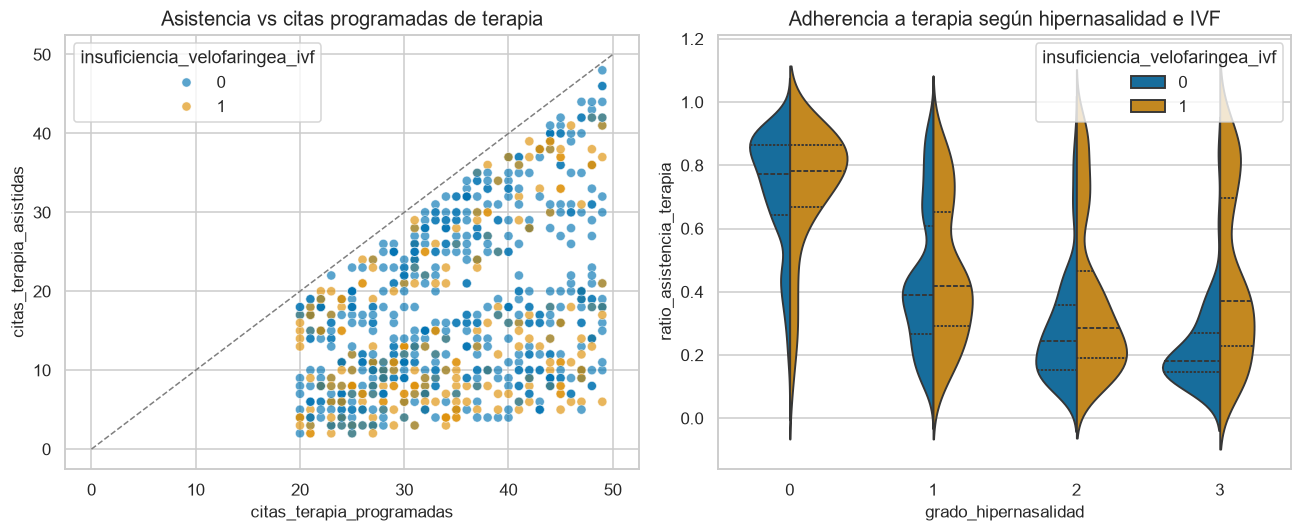

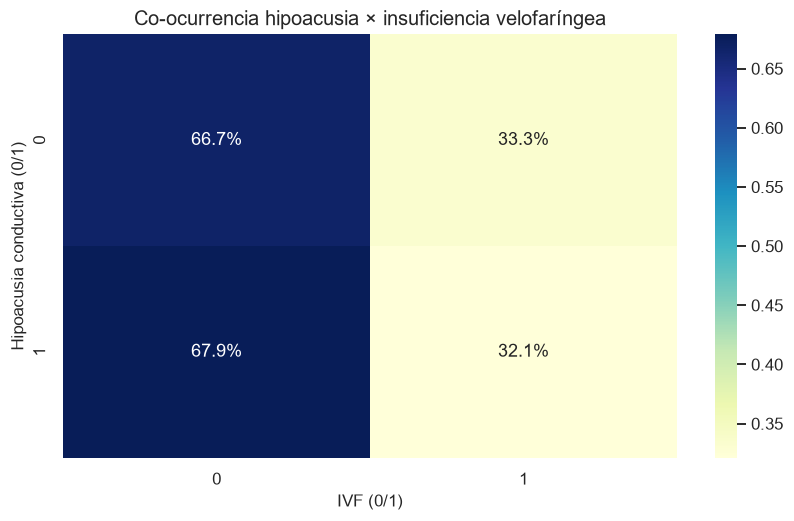

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(
    data=df.sample(min(len(df), 800), random_state=42),
    x="citas_terapia_programadas",
    y="citas_terapia_asistidas",
    hue="insuficiencia_velofaringea_ivf",
    alpha=0.65,
    ax=axes[0],
)
axes[0].plot([0, 50], [0, 50], ls="--", c="gray", lw=1)
axes[0].set_title("Asistencia vs citas programadas de terapia")

sns.violinplot(
    data=df,
    x="grado_hipernasalidad",
    y="ratio_asistencia_terapia",
    hue="insuficiencia_velofaringea_ivf",
    split=True,
    inner="quartile",
    ax=axes[1],
)
axes[1].set_title("Adherencia a terapia según hipernasalidad e IVF")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
heat = pd.crosstab(
    df["hipoacusia_conductiva"].astype(int),
    df["insuficiencia_velofaringea_ivf"].astype(int),
    normalize="index",
)
sns.heatmap(heat, annot=True, fmt=".1%", cmap="YlGnBu", ax=ax)
ax.set_xlabel("IVF (0/1)")
ax.set_ylabel("Hipoacusia conductiva (0/1)")
ax.set_title("Co-ocurrencia hipoacusia × insuficiencia velofaríngea")
plt.show()


## Estado nutricional a los 2 años y tipo de fisura


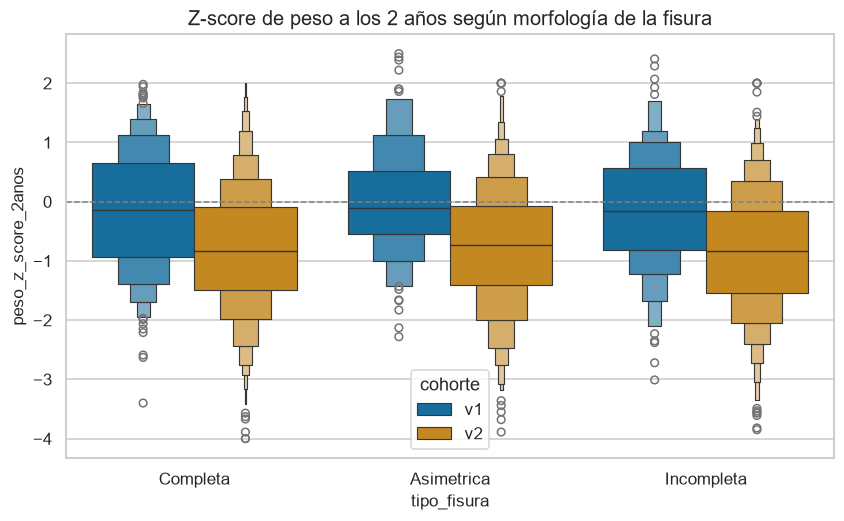

,cohorte,tipo_fisura,n,queiloplastia_mediana,palatoplastia_mediana,ratio_terapia,tasa_ivf,z_peso
0,v1,Asimetrica,106,5.0,13.5,0.783,0.283,0.007
1,v1,Completa,241,5.0,13.0,0.779,0.299,-0.147
2,v1,Incompleta,153,5.0,13.0,0.772,0.288,-0.154
3,v2,Asimetrica,633,4.5,12.8,0.422,0.327,-0.754
4,v2,Completa,1499,4.5,12.5,0.432,0.323,-0.800
5,v2,Incompleta,868,4.5,12.5,0.412,0.359,-0.846


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxenplot(
    data=df, x="tipo_fisura", y="peso_z_score_2anos", hue="cohorte", ax=ax,
)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set_title("Z-score de peso a los 2 años según morfología de la fisura")
plt.show()

resumen = (
    df.groupby(["cohorte", "tipo_fisura"], as_index=False)
    .agg(
        n=("id_paciente", "count"),
        queiloplastia_mediana=("edad_queiloplastia_meses", "median"),
        palatoplastia_mediana=("edad_palatoplastia_meses", "median"),
        ratio_terapia=("ratio_asistencia_terapia", "mean"),
        tasa_ivf=("insuficiencia_velofaringea_ivf", "mean"),
        z_peso=("peso_z_score_2anos", "mean"),
    )
    .round(3)
)
resumen


## Conclusiones clínicas
1. Los hitos de **labio y paladar** se concentran en el primer y segundo año de vida;
   el intervalo entre cirugías es un indicador de continuidad del protocolo, no de
   deserción por sí mismo.
2. La **carga de complicaciones** (fístula, dehiscencia) se asocia con más procedimientos:
   es una variable de exposición clínica, no un sustituto del no-show.
3. La **asistencia a terapia** y la IVF describen la fase larga del tratamiento:
   pacientes con hipernasalidad alta e IVF requieren seguimiento fonoaudiológico
   prolongado, donde la deserción es más costosa funcionalmente.
4. El z-score ponderal a los 2 años resume dificultad alimentaria preoperatoria y
   acceso a controles; debe leerse junto al contexto socioeconómico (notebook 02).
